# 1-board: ntc-curve

Grade the board NTC's reading against the thermocouple, and hand the firmware's design the conversion it will carry, so a board temperature in the log is a temperature.

## Purpose

The firmware will derate and cut off on the board NTC, a negative temperature coefficient thermistor, which is a resistor whose value falls as it warms, and the winding thermometer leans on the same part as the case's temperature. The conversion from the NTC's raw count to degrees that the firmware will carry is designed from this notebook. This experiment puts the thermocouple on the board next to the NTC, warms the board through the range the thermal experiments use, and grades the part's nominal beta equation, 10 kohm at 25 C and 3950 K from the board registry, against what the thermocouple reads. It then fits the quadratic in the count that a fixed-point implementation can carry, through the nominal beta equation, over the range a board meets in service, and reports what that form costs. The opamp-temperature experiment reads the conversion this notebook settles on from its result file, to turn the NTC counts in its laps into degrees.

## Procedure

The board is taped with kapton to the heated bed of a Prusa MK3S printer with the steel sheet off, so it sits on the bed's own surface with a small air gap under it where the connector pins poke down. The thermocouple tip is taped with kapton to the board's top surface next to the NTC, with no thermal paste and no copper contact. The board runs on the DPS at 7.65 V, which is about 7.4 V on the rail after the feed diode, with the bridge off. The DMM logs the thermocouple throughout. `capture.py` polls the NTC's raw count every two seconds and writes a mark at each prompt. A bare 5 ohm power resistor also sat on the bed, unpowered, and plays no part in this run.

1. The board, the thermocouple and the bed as above, the bed off. The DMM on temperature in C, Bluetooth on.
2. `capture.py`. It marks `room` and logs at room, then asks for the bed to be set at each prompt. The bed went to 60 C at the `warm` mark, to 80 C at the `hot` mark, and off at the `room again` mark, each prompt answered once the thermocouple had settled.
3. The run was ended at the `end` mark with the thermocouple at 29.1 C, before the board was back at room. The cool-down tail is slow, and the cool-down itself gives the NTC against the thermocouple at every temperature on the way down, so `room again` is a ramp in this run and not a plateau.

The bed's setpoints of 60 and 80 C put the board at about 47 and 60 C. The bed's own thermistor sits in the heater under the air gap and reads the heater, not the board, so its log is kept as a side note on the rig and never as a temperature reference.

A second, short capture was taken right after the sitting to test the thermocouple's placement itself, `press-1`. The tip was re-taped with the same kapton and no paste onto the bed's own surface next to the board, the bed held at 80 C, the board unpowered and no NTC log. After two minutes bare under its tape, a folded kitchen towel was laid over the taped tip, hands off, for three minutes, and then lifted. A fingertip pressed on the tape had pulled the reading down, into the finger, which is why a towel was used. The marks were placed from the trace afterwards. The question it answers is whether a tip taped without paste reads the surface it sits on or something between that surface and the room air.

## Data

Four files in the capture folder, all on the host clock.

- `dmm.csv`: the thermocouple's log, `t_host`, `function` (`C` throughout), `value` in C, `raw` the packet.
- `ntc.csv`: `t_host` and `ntc_raw`, the raw count every two seconds.
- `marks.csv`: the host time of each prompt, `room`, `warm`, `hot`, `room again` and `end`. A mark names the plateau that starts at it, so each plateau ends at the next mark.
- `heater.csv`: `t_host`, `bed_c` and `target_c` every ten seconds, the bed's own thermistor and its setpoint as the host read them from the printer.

Three files in the `press-1` folder beside it, the same `dmm.csv` and `heater.csv` columns, and `marks.csv` with the marks `taped on the bed, bare`, `handled`, `taped on the bed, bare again`, `pad over the tip`, `pad off` and `end`.

### The logs

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import b41t, boards, results
from oscnb import ntc as ntcmod
from oscnb.display import show

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"   # the house colours
BOARD = boards.BOARDS[boards.DEFAULT]                                   # the board, with the NTC's pull-up, R25 and beta as the registry holds them
CAPTURE = (Path("../../../telemetry") / BOARD.key / "ntc-curve" / "capture-1").resolve()
print(BOARD.key, "from", results.rel(CAPTURE))
print(f"NTC: {BOARD.ntc_r25_ohm} ohm at 25 C, beta {BOARD.ntc_beta} K, {BOARD.ntc_pullup_ohm} ohm pull-up to the {BOARD.vdd_mv / 1e3:.1f} V rail")

dev-v006-2A-D from telemetry/dev-v006-2A-D/ntc-curve/capture-1
NTC: 10000 ohm at 25 C, beta 3950 K, 10000 ohm pull-up to the 3.3 V rail


In [2]:
dmm = b41t.load(CAPTURE / "dmm.csv")                              # one row per meter packet: t_host, function, value (C), raw
n = pd.read_csv(CAPTURE / "ntc.csv")                              # one row per poll: t_host, ntc_raw
marks = pd.read_csv(CAPTURE / "marks.csv")                        # the host time of each prompt
heater = pd.read_csv(CAPTURE / "heater.csv")                      # the bed's own thermistor and setpoint, a side note on the rig
TC = results.read("0-instruments", "thermocouple")                # the thermocouple's offset and slope against ice and boiling water
DMM = results.read("0-instruments", "dmm")                        # the meter's lag and its temperature class from the manual
dmm = dmm[dmm["function"] == "C"].dropna(subset=["value"]).reset_index(drop=True)
dmm["t_c"] = (dmm["value"] - TC["offset_c"]["value"]) / TC["slope"]["value"]   # the stage 0 correction: t = (reading - offset) / slope
dmm["t_true"] = dmm["t_host"] - DMM["lag_s"]["value"]             # the moment the meter read it, 20 ms before the packet landed
CLASS_PCT, CLASS_FIXED = DMM["accuracy"]["temp_c"]["pct"]["value"], DMM["accuracy"]["temp_c"]["fixed"]["value"]
meter_class = lambda t_c: CLASS_FIXED + CLASS_PCT / 100 * np.asarray(t_c, float)   # the meter's class in C at a reading
mt = marks.set_index("mark")["t_host"]                            # the marks by name
t0 = mt["room"]                                                   # the room mark, time zero for the run
show(dmm); show(n); show(heater)
show(marks.assign(minutes=(marks["t_host"] - t0) / 60), n=None)
print(f"{len(dmm)} thermocouple packets, {len(n)} NTC polls, {len(heater)} bed rows over {(n['t_host'].iloc[-1] - t0) / 60:.1f} min")
print(f"longest gap: thermocouple {np.diff(dmm['t_host']).max():.2f} s, NTC {np.diff(n['t_host']).max():.2f} s, bed {np.diff(heater['t_host']).max():.1f} s")
print(f"thermocouple correction: offset {TC['offset_c']['value']:.1f} C, slope {TC['slope']['value']:.4f}; meter lag {DMM['lag_s']['value'] * 1e3:.0f} ms; "
      f"meter class {CLASS_PCT:g} % of the reading + {CLASS_FIXED:g} C")

,t_host,function,value,raw,t,t_c,t_true
0,11:23:34.250,C,23.400,21f20000ea00,0.000,23.488,1793125414.230
1,11:23:34.727,C,23.400,21f20000ea00,0.478,23.488,1793125414.708
2,11:23:35.237,C,23.400,21f20000ea00,0.988,23.488,1793125415.218
3,11:23:35.749,C,23.400,21f20000ea00,1.499,23.488,1793125415.729
4,11:23:36.230,C,23.400,21f20000ea00,1.980,23.488,1793125416.210


,t_host,ntc_raw
0,11:23:33.743,2094
1,11:23:35.832,2094
2,11:23:37.924,2095
3,11:23:40.036,2092
4,11:23:42.141,2091


,t_host,bed_c,target_c
0,11:20:27.938,22.300,0.000
1,11:20:38.030,22.100,0.000
2,11:20:48.118,22.700,0.000
3,11:20:58.201,22.900,0.000
4,11:21:08.263,22.700,0.000


,t_host,mark,minutes
0,11:23:33.743,room,0.000
1,11:26:37.033,warm,3.055
2,11:39:04.927,hot,15.520
3,11:49:28.897,room again,25.919
4,12:10:57.497,end,47.396


5687 thermocouple packets, 1358 NTC polls, 305 bed rows over 47.4 min
longest gap: thermocouple 0.93 s, NTC 2.18 s, bed 10.4 s
thermocouple correction: offset 0.1 C, slope 0.9920; meter lag 20 ms; meter class 1 % of the reading + 0.5 C


The thermocouple reads in 0.1 C steps about twice a second, the NTC every two seconds and the bed every ten. No log has a gap longer than its own interval and a little. The bed's log starts three minutes before the room mark and ends half a minute after the end mark, since the host read it from the printer on its own loop. The marks are listed in minutes from the room mark, which is time zero for every figure of the run.

### The run

The whole run on one time axis, the corrected thermocouple, the NTC's raw count and the bed's own log on a panel of its own, with the marks and the three plateau windows shaded. The thing to see is where the board sits still and where it is moving, and how far the bed sits above the board while it heats.

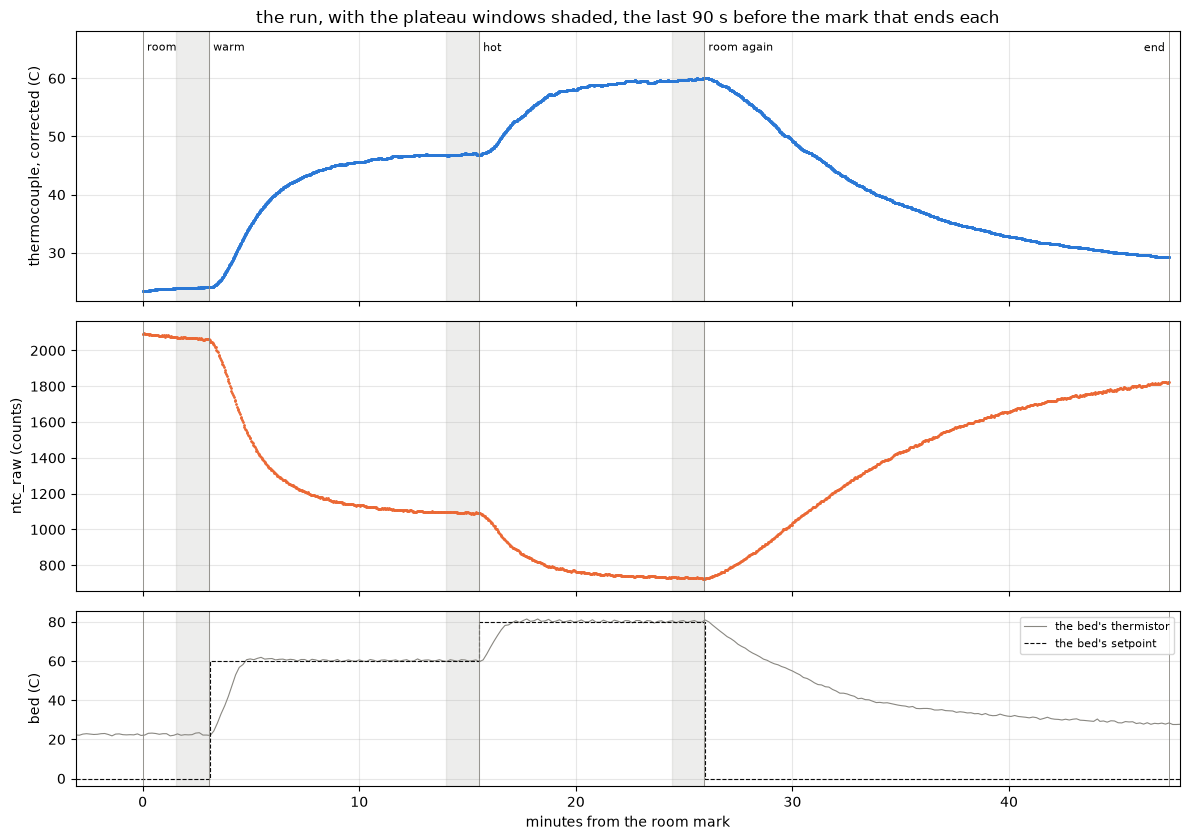

In [3]:
W = 90.0                                                          # a plateau is the last 90 s before the mark that ends it
ENDS = {"room": "warm", "warm": "hot", "hot": "room again"}       # each plateau and the mark that ends it
tm = lambda t: (np.asarray(t, float) - t0) / 60                   # host seconds to minutes from the room mark
fig, ax = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True, gridspec_kw={"height_ratios": [2, 2, 1.3]})
ax[0].plot(tm(dmm["t_true"]), dmm["t_c"], ".", ms=2, color=BLUE); ax[0].set_ylabel("thermocouple, corrected (C)")
ax[1].plot(tm(n["t_host"]), n["ntc_raw"], ".", ms=2, color=ORANGE); ax[1].set_ylabel("ntc_raw (counts)")
ax[2].plot(tm(heater["t_host"]), heater["bed_c"], "-", lw=0.8, color=MUTED, label="the bed's thermistor")
ax[2].step(tm(heater["t_host"]), heater["target_c"], where="post", lw=0.8, ls="--", color=INK, label="the bed's setpoint")
ax[2].set_ylabel("bed (C)"); ax[2].legend(fontsize=8, loc="upper right")
for a in ax:
    for p, m in ENDS.items():                                     # the plateau windows
        a.axvspan(tm(mt[m] - W), tm(mt[m]), color=MUTED, alpha=0.15)
    for _, m in marks.iterrows():                                 # the marks
        a.axvline(tm(m["t_host"]), color=MUTED, lw=0.6)
    a.grid(alpha=0.3)
for _, m in marks.iterrows():                                     # the mark names along the top of the first panel
    end = m["mark"] == "end"
    ax[0].text(tm(m["t_host"]) + (-0.2 if end else 0.2), 0.96, m["mark"], fontsize=8, va="top", ha="right" if end else "left", transform=ax[0].get_xaxis_transform())
ax[0].set_ylim(top=dmm["t_c"].max() + 8)                          # headroom for the mark names over the hot plateau
ax[0].set_title("the run, with the plateau windows shaded, the last 90 s before the mark that ends each")
ax[-1].set_xlabel("minutes from the room mark"); ax[-1].set_xlim(tm(heater["t_host"].iloc[0]), tm(heater["t_host"].iloc[-1]))
plt.tight_layout(); plt.show()

Three minutes at room, then two steps of the bed, each followed by a plateau of about ten minutes, then the bed off and twenty minutes of cool-down that stops at 29 C. The NTC's count falls as the board warms, which is the thermistor's sign. The bed's thermistor overshoots each step by a degree and settles at the setpoint within two minutes, while the board takes most of each ten minutes to come near its plateau, and the bed sits 13 C over the board on the warm plateau and 20 C over it on the hot plateau. On the cool-down the bed falls faster than the board at first and ends below it, so the last twenty minutes cross the same temperatures as the heat-up with the heat flowing the other way. That is the lever the gradient section uses.

## Method

The thermocouple's reading, corrected by its stage 0 offset and slope and shifted by the DMM's lag, is interpolated onto each NTC poll, so every row of the analysis carries a count and a temperature taken together. The bed's log is interpolated onto the same rows as a side column.

A plateau is the last 90 s before the mark that ends it, three of them, `room`, `warm` and `hot`. The rows from the `room again` mark to the end are the cool-down. The rows between the `warm` and the `room again` marks that are not in a plateau are the heat-up ramps.

Three conversions are compared with the thermocouple.

1. The part's beta equation at the nominal beta and R25 from the board registry, $1/T = 1/T_{25} + \ln(R / R_{25}) / \beta$ with $T$ in kelvin and $R$ the thermistor's resistance from the count and the pull-up. This is the conversion being graded.
2. The same equation with $\beta$ refitted through the measured points.
3. A quadratic in the count refitted through the measured points, $t = t_{ref} + k_1 d + k_2 d^2$ with $d$ the count below a reference count of 2048. These two refits are what this thermocouple placement gives, and they are not design constants.

The fits use the plateaus and the cool-down and leave the heat-up ramps out. On the way up the board rose at up to 7 C per minute, and the thermocouple tip, taped on top, follows that rise a few seconds behind the copper the NTC sits on, so a heat-up row pairs a count with a temperature that is a little stale. The cool-down runs under 4 C per minute and the plateaus do not move. The whole run and the cool-down alone are fitted as well, as a check on how much the row choice moves the answer, and that spread is the bracket the result file carries on the refitted beta.

Each conversion is graded at the three plateaus against the meter's temperature class from the stage 0 dmm result, 1 % of the reading plus 0.5 C, which is 0.7 C at room and 1.1 C at 60 C. A conversion inside the class at every plateau is as good as this meter can tell.

The gap between the nominal beta and the thermocouple grows with temperature, and three things can make it grow. The curve itself can be off, with beta or R25 away from nominal, which gives the same gap at a given board temperature whichever way the board got there. The thermocouple tip, taped on the top surface in still air, can lose heat to the room through the tape and read under the surface by a fraction of the board's excess over the room, which grows with the board's temperature in the same way. Or the thermocouple on the top surface can read cooler than the NTC, which sits on copper on a board heated from underneath, which gives a gap that follows the bed's excess over the board rather than the board's temperature. The heat-up and the cool-down cross the same temperatures with very different bed excesses, so the two legs separate the third cause from the first two. The first two are not separated by the run, since both follow the board's temperature alone. The pad test separates them. A tip insulated from the room can only move toward the surface it sits on, never past it, so any rise under the pad is the tip's own loss, and a tip that reads the surface does not move.

The design conversion comes last. A fixed-point quadratic in the count, $t = t_{ref} + k_1 d + k_2 d^2$ with $d = 2048 - raw$, $t_{ref}$ in centidegrees, $k_1$ in Q8.8 and $k_2$ in Q24, is the cheapest form a small chip can carry, two multiplies and no logarithm. It is fitted through the nominal beta equation itself, with no thermocouple data in it, on a grid of temperatures 0.1 C apart over 20 to 100 C, the range a board meets in service, and again over 20 to 60 C as the tighter alternative. Each fit's residual against the beta equation is read at every integer count in its range, which is what the form costs.

### The plateaus

The two sensors and the bed over each plateau window, with the nominal beta beside the thermocouple and the meter's class at that temperature.

In [4]:
n["t_c"] = np.interp(n["t_host"], dmm["t_true"], dmm["t_c"])                  # the corrected thermocouple at each poll
n["t_raw_c"] = np.interp(n["t_host"], dmm["t_true"], dmm["value"])            # the meter's own reading, for the table only
n["bed_c"] = np.interp(n["t_host"], heater["t_host"], heater["bed_c"])        # the bed's thermistor at each poll
n["bed_excess"] = n["bed_c"] - n["t_c"]                                       # how far the bed sits over the board
t_ahead = np.interp(n["t_host"] + 30, dmm["t_true"], dmm["t_c"])              # the thermocouple 30 s later...
t_behind = np.interp(n["t_host"] - 30, dmm["t_true"], dmm["t_c"])             # ...and 30 s earlier
n["rate"] = (t_ahead - t_behind)                                              # its rate over a centered minute, in C per minute
n["beta_c"] = BOARD.ntc_c_beta(n["ntc_raw"])                                  # the part's beta equation at the nominal beta and R25
n["gap"] = n["beta_c"] - n["t_c"]                                             # the nominal beta less the thermocouple
n["plateau"] = ""
for p, m in ENDS.items():                                                     # label the plateau rows
    n.loc[(n["t_host"] >= mt[m] - W) & (n["t_host"] < mt[m]), "plateau"] = p
n["leg"] = np.where(n["t_host"] >= mt["room again"], "cool-down", "heat-up")  # before the bed went off, or after
FIT = (n["plateau"] != "") | (n["leg"] == "cool-down")                        # the fit rows: the plateaus and the cool-down
rows = []
for p in ENDS:
    w = n[n["plateau"] == p]
    creep = np.polyfit(w["t_host"] - w["t_host"].iloc[0], w["t_c"], 1)[0] * 60   # how fast the thermocouple still moved over the window
    rows.append({"plateau": p, "rows": len(w), "thermocouple_c": w["t_c"].mean(), "tc_sd": w["t_c"].std(), "creep_c_per_min": creep,
                 "ntc_raw": w["ntc_raw"].mean(), "raw_sd": w["ntc_raw"].std(), "bed_c": w["bed_c"].mean(),
                 "beta_c": w["beta_c"].mean(), "meter_class_c": meter_class(w["t_c"].mean())})
P = pd.DataFrame(rows).set_index("plateau")
show(P, n=None)
print(f"fit rows: {int(FIT.sum())} of {len(n)} ({int((n['plateau'] != '').sum())} on the plateaus, {int((n['leg'] == 'cool-down').sum())} on the cool-down); "
      f"the thermocouple's correction adds {P['thermocouple_c'].iloc[0] - n[n['plateau'] == 'room']['t_raw_c'].mean():+.2f} C at room and "
      f"{P['thermocouple_c'].iloc[2] - n[n['plateau'] == 'hot']['t_raw_c'].mean():+.2f} C at the hot plateau")

,rows,thermocouple_c,tc_sd,creep_c_per_min,ntc_raw,raw_sd,bed_c,beta_c,meter_class_c
plateau,,,,,,,,,
room,43,23.987,0.072,0.151,2068.512,3.942,22.541,24.550,0.740
warm,43,46.904,0.105,0.186,1093.977,3.004,60.308,49.592,0.969
hot,43,59.766,0.124,0.248,730.326,3.068,80.202,63.867,1.098


fit rows: 743 of 1358 (129 on the plateaus, 614 on the cool-down); the thermocouple's correction adds +0.09 C at room and +0.38 C at the hot plateau


The thermocouple's standard deviation over a window is about 0.1 C, which is its reading step, and the NTC's is 3 to 4 counts, which is 0.1 to 0.2 C at the curve's slope. The plateaus were still creeping up by 0.15 to 0.25 C per minute when the bed was stepped, so each plateau mean is a point on a slow ramp, about 0.2 C under where the window ends, and the thermocouple is reading the board's creep, not its own settling, since it settles in air within a minute. The stage 0 correction adds 0.1 C at room and 0.4 C at the hot plateau.

The nominal beta sits 0.6 C over the thermocouple at room, 2.7 C over at the warm plateau and 4.1 C over at the hot one, a gap that grows with temperature. The next figure shows it over the whole run.

## Results

### The curve

The raw count against the corrected thermocouple with the three curves through it, and the error of each conversion against temperature over the fit rows, with the meter's class as the shaded band. The heat-up ramp rows are drawn muted on the left and left out on the right. The thing to see is which curves stay inside the band at every temperature.

against the thermocouple over the fit rows, and at each plateau (the meter's class is 0.74, 0.97, 1.10 C there)
  nominal beta             mean +1.71 C, rms 1.98, worst 4.31 | plateaus +0.56, +2.69, +4.10
  beta refit, 4331 K       mean +0.12 C, rms 0.32, worst 0.74 | plateaus +0.60, +0.36, +0.28
  quadratic refit          mean -0.00 C, rms 0.30, worst 0.97 | plateaus +0.47, +0.82, -0.10

the row choice as a check
  plateaus and cool-down (the fit rows)  beta 4331 K, quadratic t_ref 2482 cC, k1 452 (Q8.8), k2 11195 (Q24)
  whole run                              beta 4383 K, quadratic t_ref 2472 cC, k1 425 (Q8.8), k2 12345 (Q24)
  cool-down alone                        beta 4316 K, quadratic t_ref 2534 cC, k1 414 (Q8.8), k2 12784 (Q24)
  plateaus alone                         beta 4371 K, quadratic t_ref 2430 cC, k1 390 (Q8.8), k2 14853 (Q24)

beta nominal 3950 K, refit 4331 K (+9.7 %), 4316 to 4383 across the row choices


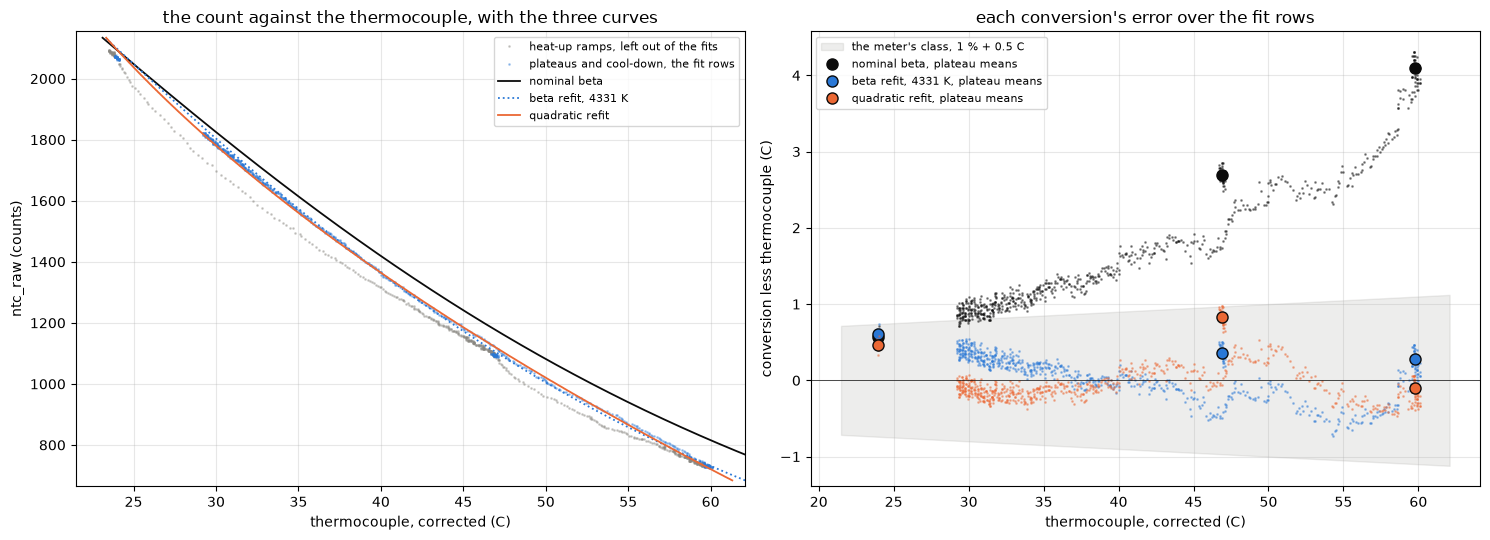

In [5]:
RAW_REF = 2048                                                                  # the reference count, 25 C on the nominal curve
beta_c_of = lambda raw, beta: 1 / (1 / 298.15 + np.log(BOARD.ntc_ohm(raw) / BOARD.ntc_r25_ohm) / beta) - 273.15   # the beta equation at any beta

def refit(rows_):
    # the refitted beta and the refitted quadratic through one set of rows
    beta = ntcmod.fit_beta(BOARD.ntc_ohm(rows_["ntc_raw"]), rows_["t_c"], BOARD.ntc_r25_ohm)
    quad = ntcmod.fit_quadratic(rows_["ntc_raw"], rows_["t_c"], RAW_REF)
    return beta, quad

fit = n[FIT]
beta_fit, quad = refit(fit)                                                     # the fits the result file carries
checks = {"plateaus and cool-down (the fit rows)": (beta_fit, quad), "whole run": refit(n), "cool-down alone": refit(n[n["leg"] == "cool-down"]),
          "plateaus alone": refit(n[n["plateau"] != ""])}
n["beta_fit_c"] = beta_c_of(n["ntc_raw"], beta_fit)
n["quad_c"] = ntcmod.quadratic_cc(n["ntc_raw"], RAW_REF, *quad) / 100
fit = n[FIT]                                                                    # the fit rows again, now with the refits as columns
CONV = {"beta_c": ("nominal beta", INK, "-"), "beta_fit_c": (f"beta refit, {beta_fit:.0f} K", BLUE, ":"), "quad_c": ("quadratic refit", ORANGE, "-")}
for c in CONV:
    P[c.replace("_c", "_err")] = [n[n["plateau"] == p][c].mean() - P.loc[p, "thermocouple_c"] for p in P.index]   # each conversion's error at each plateau
err = {c: fit[c] - fit["t_c"] for c in CONV}                                    # each conversion's error over the fit rows
print("against the thermocouple over the fit rows, and at each plateau (the meter's class is "
      + ", ".join(f"{P.loc[p, 'meter_class_c']:.2f}" for p in P.index) + " C there)")
for c, (name, _, _) in CONV.items():
    e = err[c]
    print(f"  {name:24s} mean {e.mean():+.2f} C, rms {np.sqrt((e ** 2).mean()):.2f}, worst {e.abs().max():.2f} | plateaus "
          + ", ".join(f"{P.loc[p, c.replace('_c', '_err')]:+.2f}" for p in P.index))
print("\nthe row choice as a check")
for name, (b, qd) in checks.items():
    print(f"  {name:38s} beta {b:.0f} K, quadratic t_ref {qd[0]} cC, k1 {qd[1]} (Q8.8), k2 {qd[2]} (Q24)")
print(f"\nbeta nominal {BOARD.ntc_beta} K, refit {beta_fit:.0f} K ({(beta_fit / BOARD.ntc_beta - 1) * 100:+.1f} %), "
      f"{min(b for b, _ in checks.values()):.0f} to {max(b for b, _ in checks.values()):.0f} across the row choices")

grid = np.arange(int(n["ntc_raw"].min()) - 40, int(n["ntc_raw"].max()) + 40)   # a count axis for the curves
curve = {"beta_c": BOARD.ntc_c_beta(grid), "beta_fit_c": beta_c_of(grid, beta_fit), "quad_c": ntcmod.quadratic_cc(grid, RAW_REF, *quad) / 100}
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ramp = n[~FIT]
ax[0].plot(ramp["t_c"], ramp["ntc_raw"], ".", ms=2, color=MUTED, alpha=0.35, label="heat-up ramps, left out of the fits")
ax[0].plot(fit["t_c"], fit["ntc_raw"], ".", ms=2, color=BLUE, alpha=0.35, label="plateaus and cool-down, the fit rows")
for c, (name, col, ls) in CONV.items():
    ax[0].plot(curve[c], grid, ls, color=col, lw=1.3, label=name)
ax[0].set_xlim(n["t_c"].min() - 2, n["t_c"].max() + 2); ax[0].set_ylim(n["ntc_raw"].min() - 60, n["ntc_raw"].max() + 60)
ax[0].set_xlabel("thermocouple, corrected (C)"); ax[0].set_ylabel("ntc_raw (counts)"); ax[0].set_title("the count against the thermocouple, with the three curves")
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
tt = np.linspace(n["t_c"].min() - 2, n["t_c"].max() + 2, 50)
ax[1].fill_between(tt, -meter_class(tt), meter_class(tt), color=MUTED, alpha=0.15, label="the meter's class, 1 % + 0.5 C")
for c, (name, col, ls) in CONV.items():
    ax[1].plot(fit["t_c"], err[c], ".", ms=2, color=col, alpha=0.4)
    ax[1].plot(P["thermocouple_c"], P[c.replace("_c", "_err")], "o", ms=8, color=col, mec=INK, label=f"{name}, plateau means")
ax[1].axhline(0, color=INK, lw=0.5)
ax[1].set_xlabel("thermocouple, corrected (C)"); ax[1].set_ylabel("conversion less thermocouple (C)"); ax[1].set_title("each conversion's error over the fit rows")
ax[1].legend(fontsize=8, loc="upper left"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

On the left, the fit rows lie on one curve to the eye, and the heat-up rows sit a little to the left of it, which is the thermocouple reading behind the copper on the way up. The nominal beta runs under the points from 40 C on, which means it reads a count as too warm there. The two refits run through the points.

On the right, the nominal beta reads 0.6, 2.7 and 4.1 C high at the plateaus, outside the class from about 35 C up. The refitted beta, 4331 K against the part's 3950 K, leaves +0.6, +0.4 and +0.3 C at the plateaus, and the refitted quadratic leaves +0.5, +0.8 and -0.1 C, both inside the class at every plateau and over the fit rows. Both refits leave a few tenths of a degree more at the warm plateau than on the cool-down at the same temperature, which is the gradient the next section measures, and a few tenths at room, which is inside the class at room.

The refitted beta moves from 4316 to 4383 K with the row choice, the cool-down alone at the low end and the whole run at the high end, since the heat-up rows pull the curve toward their stale temperatures. That spread is 0.3 C at 60 C and is the bracket the result file carries. A beta 10 % over the part's label is a lot for a 1 % part, and the refit absorbs anything else that follows the board's temperature, the pull-up's value, the R25, the thermocouple tip's own loss to the room air, and whatever the gradient leaves in the plateaus. The pad test below shows the tip's loss is the large part of it, so the refit corrects the NTC toward a thermocouple that reads low, and a board temperature read through it sits under the copper's by up to that part, about 2.7 C at 60 C.

### Heat-up against cool-down

The nominal beta's gap over the thermocouple against the board's temperature, the heat-up and the cool-down as two series, with the bed's excess over the board and the thermocouple's rate under it on the same axis. The dashed line runs through the cool-down rows where the bed is at or below the board, where no heat flows up through the board and the thermocouple is reading the same thing the NTC is. The thing to see is where the two legs' gaps part and what the bed is doing there.

cool-down with the bed at or below the board, 419 rows over 29 to 42 C: gap = 0.57 + 0.0611 +/- 0.0012 C per C over 25 C, rms 0.09 C

the gradient, with that line held: what is left of the gap against the bed's excess over the board
  slow rows (under 1 C/min)     754 rows: 0.0601 +/- 0.0005 C per C of bed excess (intercept +0.05, rms 0.14); both free: slope 0.0721, gradient 0.0460, rms 0.14
  cool-down alone               614 rows: 0.0470 +/- 0.0010 C per C of bed excess (intercept +0.03, rms 0.13); both free: slope 0.0495, gradient 0.0661, rms 0.12
  the three plateaus            129 rows: 0.0598 +/- 0.0012 C per C of bed excess (intercept +0.10, rms 0.13)

45 to 50 C, the two legs directly: heat-up gap 2.75 C with the bed 14.6 C over, cool-down 2.03 C with the bed 3.5 C over: 0.0647 C per C
warm plateau: bed 13.4 C over the board, the gradient's share 0.8 C (0.6 to 0.9), the line's 1.9 C, measured 2.7 C
hot plateau: bed 20.4 C over the board, the gradient's share 1.2 C (0.9 to 1.4),

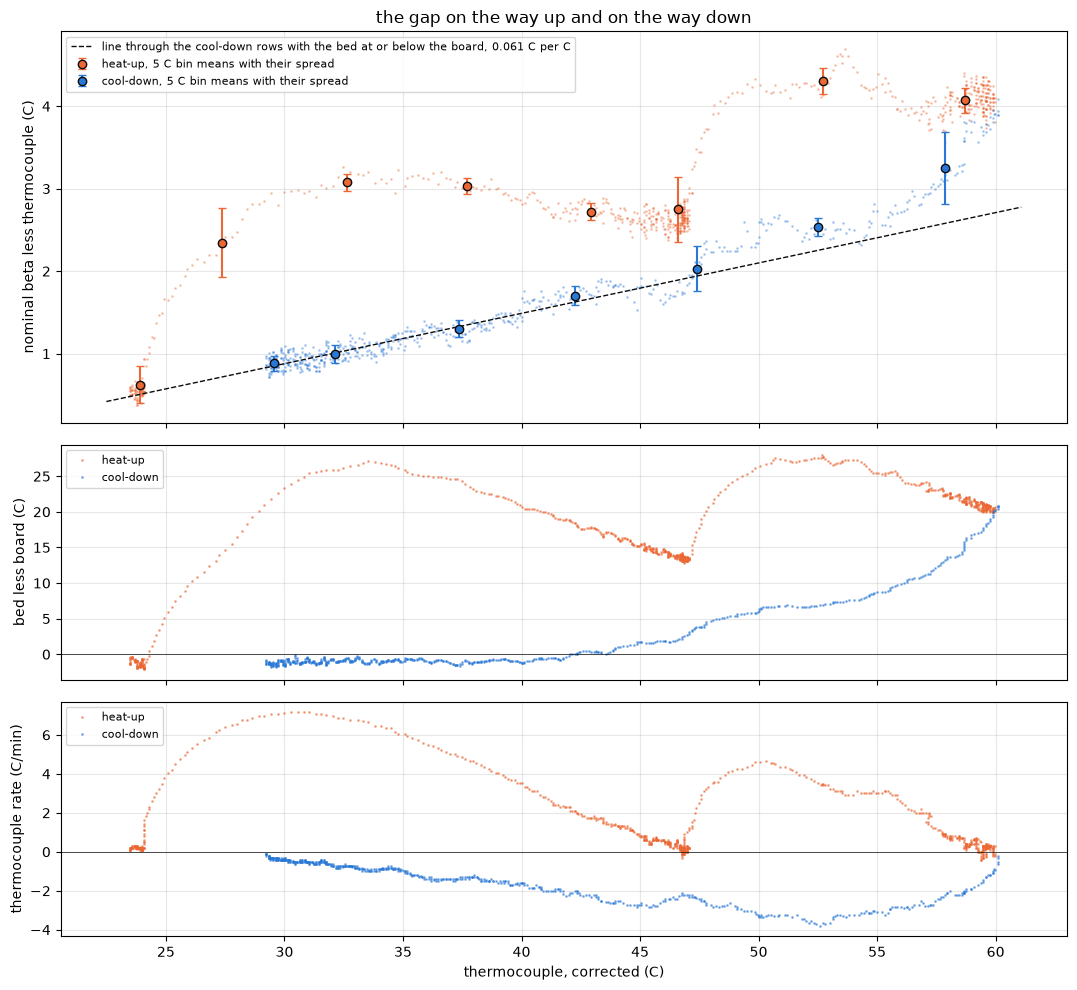

In [6]:
def plane(rows_, cols, y="gap"):
    # least squares of column y on the given columns with an intercept, with standard errors and the rms residual
    X = np.column_stack([np.ones(len(rows_))] + [rows_[c].to_numpy(float) for c in cols]); y = rows_[y].to_numpy(float)
    coef, *_ = np.linalg.lstsq(X, y, rcond=None); r = y - X @ coef
    se = np.sqrt(np.diag(np.linalg.inv(X.T @ X)) * (r @ r) / (len(y) - X.shape[1]))
    return dict(zip(["const"] + cols, coef)), dict(zip(["const"] + cols, se)), float(np.sqrt((r ** 2).mean()))

n["t25"] = n["t_c"] - 25                                                      # the board's temperature over 25 C, the beta equation's anchor
nograd = n[(n["leg"] == "cool-down") & (n["bed_excess"] <= 0)]                # the bed at or below the board: no heat flowing up through it
c0, s0, r0 = plane(nograd, ["t25"])                                           # the part of the gap that follows the board, a line through those rows
n["over_line"] = n["gap"] - (c0["const"] + c0["t25"] * n["t25"])             # what is left of the gap once that line is taken out
slope = c0["t25"]
sets = {"slow rows (under 1 C/min)": n[n["rate"].abs() < 1.0], "cool-down alone": n[n["leg"] == "cool-down"], "the three plateaus": n[n["plateau"] != ""]}
print(f"cool-down with the bed at or below the board, {len(nograd)} rows over {nograd['t_c'].min():.0f} to {nograd['t_c'].max():.0f} C: "
      f"gap = {c0['const']:.2f} + {slope:.4f} +/- {s0['t25']:.4f} C per C over 25 C, rms {r0:.2f} C")
print("\nthe gradient, with that line held: what is left of the gap against the bed's excess over the board")
held, free = {}, {}
for name, sub in sets.items():
    cg, sg, rg = plane(sub, ["bed_excess"], y="over_line")                    # the gradient alone, the line held
    held[name] = cg["bed_excess"]
    line = f"  {name:28s} {len(sub):4d} rows: {cg['bed_excess']:.4f} +/- {sg['bed_excess']:.4f} C per C of bed excess (intercept {cg['const']:+.2f}, rms {rg:.2f})"
    if name != "the three plateaus":                                          # three clusters do not pin a plane, so the free check skips them
        cf, sf, rf = plane(sub, ["t25", "bed_excess"])                        # the line's slope and the gradient both free, as a check
        free[name] = (cf["t25"], cf["bed_excess"])
        line += f"; both free: slope {cf['t25']:.4f}, gradient {cf['bed_excess']:.4f}, rms {rf:.2f}"
    print(line)
grad = held["slow rows (under 1 C/min)"]
grad_lo, grad_hi = min(list(held.values()) + [g for _, g in free.values()]), max(list(held.values()) + [g for _, g in free.values()])
slope_lo, slope_hi = min([slope] + [s for s, _ in free.values()]), max([slope] + [s for s, _ in free.values()])
n["bin"] = (n["t_c"] // 5) * 5                                                # 5 C bins by the thermocouple
bins = n.groupby(["leg", "bin"]).agg(t_mid=("t_c", "mean"), gap=("gap", "mean"), gap_sd=("gap", "std"), bed_excess=("bed_excess", "mean"),
                                     rate=("rate", "mean"), rows=("gap", "size")).reset_index()
bins = bins[bins["rows"] >= 10]                                               # a bin needs a few rows to mean anything
bins["predicted"] = c0["const"] + slope * (bins["t_mid"] - 25) + grad * bins["bed_excess"]   # the line plus the gradient
bins["left"] = bins["gap"] - bins["predicted"]                                # what neither accounts for, the lag on a ramp
pair = bins[bins["bin"] == 45].set_index("leg")                               # the one bin both legs cross slowly with the bed in different places
print(f"\n45 to 50 C, the two legs directly: heat-up gap {pair.loc['heat-up', 'gap']:.2f} C with the bed {pair.loc['heat-up', 'bed_excess']:.1f} C over, "
      f"cool-down {pair.loc['cool-down', 'gap']:.2f} C with the bed {pair.loc['cool-down', 'bed_excess']:.1f} C over: "
      f"{(pair.loc['heat-up', 'gap'] - pair.loc['cool-down', 'gap']) / (pair.loc['heat-up', 'bed_excess'] - pair.loc['cool-down', 'bed_excess']):.4f} C per C")
for p in ("warm", "hot"):
    ex = P.loc[p, "bed_c"] - P.loc[p, "thermocouple_c"]
    print(f"{p} plateau: bed {ex:.1f} C over the board, the gradient's share {grad * ex:.1f} C ({grad_lo * ex:.1f} to {grad_hi * ex:.1f}), "
          f"the line's {c0['const'] + slope * (P.loc[p, 'thermocouple_c'] - 25):.1f} C, measured {P.loc[p, 'beta_err']:.1f} C")
hb = bins[(bins["leg"] == "heat-up") & (bins["bin"] >= 25) & (bins["bin"] <= 35)]   # the 25 to 40 C bins of the first ramp
print(f"heat-up bins at 25 to 40 C, rising {hb['rate'].min():.1f} to {hb['rate'].max():.1f} C/min: {hb['left'].min():.1f} to {hb['left'].max():.1f} C over the line plus the gradient")
fig, ax = plt.subplots(3, 1, figsize=(11, 10), sharex=True, gridspec_kw={"height_ratios": [2, 1.2, 1.2]})
for leg, col in (("heat-up", ORANGE), ("cool-down", BLUE)):
    g = n[n["leg"] == leg]; b = bins[bins["leg"] == leg]
    ax[0].plot(g["t_c"], g["gap"], ".", ms=2, color=col, alpha=0.3)
    ax[0].errorbar(b["t_mid"], b["gap"], yerr=b["gap_sd"], fmt="o", ms=6, color=col, mec=INK, capsize=3, label=f"{leg}, 5 C bin means with their spread")
    ax[1].plot(g["t_c"], g["bed_excess"], ".", ms=2, color=col, alpha=0.5, label=leg)
    ax[2].plot(g["t_c"], g["rate"], ".", ms=2, color=col, alpha=0.5, label=leg)
x = np.linspace(n["t_c"].min() - 1, n["t_c"].max() + 1, 10)
ax[0].plot(x, c0["const"] + c0["t25"] * (x - 25), "--", color=INK, lw=1, label=f"line through the cool-down rows with the bed at or below the board, {c0['t25']:.3f} C per C")
ax[0].set_ylabel("nominal beta less thermocouple (C)"); ax[0].set_title("the gap on the way up and on the way down"); ax[0].legend(fontsize=8, loc="upper left")
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_ylabel("bed less board (C)"); ax[1].legend(fontsize=8, loc="upper left")
ax[2].axhline(0, color=INK, lw=0.5); ax[2].set_ylabel("thermocouple rate (C/min)"); ax[2].legend(fontsize=8, loc="upper left")
ax[2].set_xlabel("thermocouple, corrected (C)")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The top panel is where the two legs part. On the cool-down below 42 C the bed sits at or under the board, nothing flows up through the board, and the gap still climbs, from 0.9 C at 29 C to 1.7 C at 42 C, along the dashed line at 0.061 +/- 0.001 C per C of board. That part of the gap does not come from the bed, with high confidence. It is the curve, or the thermocouple tip losing heat to the room air through its tape, since both follow the board's own temperature, and the pad test in the next section tells them apart. Extended to 60 C the line puts that part at about 2.7 C of the hot plateau's 4.1 C.

Where the two legs cross the same temperature with the bed in different places, the gaps part. At 45 to 50 C the heat-up, which includes the warm plateau, has the bed 15 C over the board and a gap of 2.75 C, and the cool-down has the bed 4 C over and a gap of 2.03 C. The middle panel shows the bed excess is what differs there, and the bottom panel shows the rate is small on both legs in that bin, so the lag is not what separates them. That one bin on its own gives 0.065 C of gap per C of bed excess. With the line held and what is left of the gap fitted against the bed excess, the slow rows give 0.060 +/- 0.001 C per C, the cool-down alone 0.047 and the plateaus 0.060, and with the line's slope left free as well the fits land between 0.046 and 0.066, since the two trade against each other on rows where both rise. At the hot plateau's 20 C of bed excess that is 1.2 C, 0.9 to 1.4, which with the line's 2.7 C makes 3.9 of the 4.1 C measured. The heat-up bins at 25 to 40 C, rising at 5 to 7 C per minute, sit a further 0.3 to 0.8 C over the line plus the gradient, which is the thermocouple behind the copper on the ramp. A fit with a rate term does not separate that lag from the bed excess, since the two rise together on the heat-up, so it is left as the ramp rows' excess and those rows stay out of the fits.

### The thermocouple under a pad

The pad test's trace on its own time axis, the corrected thermocouple with the marks and the means of the bare and the padded stretches drawn over their spans, and the bed's own log on a panel of its own. The handled stretch, where the tip was lifted and the reading fell as far as 0.3 C, runs off the bottom of the panel. The thing to see is how far the reading climbs once the tip is covered and how fast it falls back when the towel comes off.

bare, first 45 s             68.2 C, sd 1.1, max 72.5, 91 packets
bare again                   68.6 C, sd 1.1, max 70.1, 125 packets
pad, after the first minute  75.3 C, sd 1.5, max 78.1, 237 packets
pad, last minute             76.2 C, sd 1.2, max 78.1, 119 packets
the first 10 s after the pad came off: 72.8 C
30 to 60 s after: 67.4 C
bed over the test 80.2 C (79.5 to 80.9), the room 24.0 C from the run's room plateau, so the bed sat 56.2 C over the room
the towel raised the tip by 7.6 C (6.6 over the whole padded stretch, 9.5 at its highest), still creeping when it came off: the bare tip read at least 13 % (12 to 17 %) of the bed's excess over the room low
warm plateau: the board 22.9 C over the room, the bed's loss share would be 2.7 to 3.9 C; the part of the gap that followed the board is 1.9 C, 8 % of the board's excess
hot plateau: the board 35.8 C over the room, the bed's loss share would be 4.2 to 6.0 C; the part of the gap that followed the board is 2.7 C, 8 % of the board's e

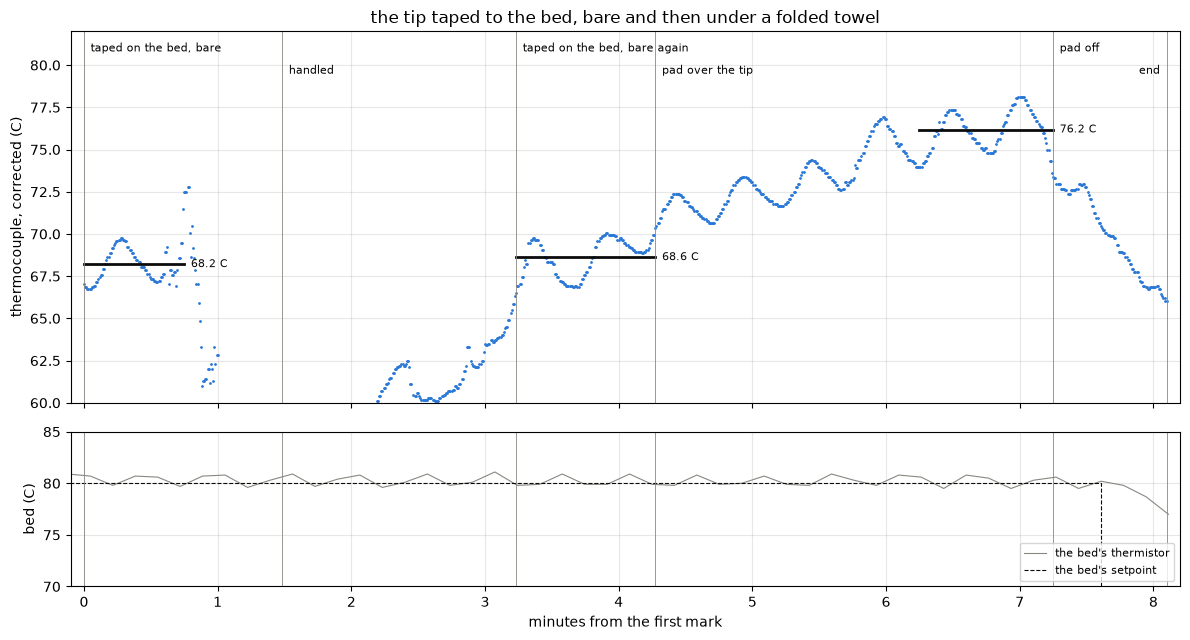

In [7]:
PRESS = CAPTURE.parent / "press-1"                                             # the pad test, taken right after the sitting
pt = b41t.load(PRESS / "dmm.csv")                                              # the thermocouple on the bed, uncorrected C
pt = pt[pt["function"] == "C"].dropna(subset=["value"]).reset_index(drop=True)
pt["t_c"] = (pt["value"] - TC["offset_c"]["value"]) / TC["slope"]["value"]     # the same stage 0 correction as the run
pt_marks = pd.read_csv(PRESS / "marks.csv"); pt_heater = pd.read_csv(PRESS / "heater.csv")
pm = pt_marks.set_index("mark")["t_host"]; p0 = pm["taped on the bed, bare"]  # time zero for this figure
ROOM_C = P.loc["room", "thermocouple_c"]                                       # the room, from the run's room plateau
SPANS = {"bare, first 45 s": (p0, p0 + 45), "bare again": (pm["taped on the bed, bare again"], pm["pad over the tip"]),
         "pad, after the first minute": (pm["pad over the tip"] + 60, pm["pad off"]), "pad, last minute": (pm["pad off"] - 60, pm["pad off"])}
def stretch(a, b):
    w = pt[(pt["t_host"] >= a) & (pt["t_host"] < b)]["t_c"]                   # one stretch of the trace
    return {"mean": w.mean(), "sd": w.std(), "max": w.max(), "n": len(w)}
st = {k_: stretch(*v) for k_, v in SPANS.items()}
for k_, s in st.items():
    print(f"{k_:28s} {s['mean']:.1f} C, sd {s['sd']:.1f}, max {s['max']:.1f}, {s['n']} packets")
bed_test = pt_heater[(pt_heater["t_host"] >= pm["taped on the bed, bare again"]) & (pt_heater["t_host"] < pm["pad off"])]["bed_c"]
bare, padded = st["bare again"], st["pad, last minute"]
pad_rise = padded["mean"] - bare["mean"]                                       # what the towel added, the last minute against the bare stretch
pad_rise_lo = st["pad, after the first minute"]["mean"] - bare["mean"]         # the padded stretch as a whole, still creeping up
pad_rise_hi = padded["max"] - bare["mean"]                                     # the highest the covered tip got
bed_excess_room = bed_test.mean() - ROOM_C                                     # how far the bed sat over the room
loss, loss_lo, loss_hi = pad_rise / bed_excess_room, pad_rise_lo / bed_excess_room, pad_rise_hi / bed_excess_room   # the tip's loss as a share of the surface's excess over the room
for lbl, a, b in (("the first 10 s after the pad came off", pm["pad off"], pm["pad off"] + 10), ("30 to 60 s after", pm["pad off"] + 30, pm["pad off"] + 60)):
    print(f"{lbl}: {stretch(a, b)['mean']:.1f} C")
print(f"bed over the test {bed_test.mean():.1f} C ({bed_test.min():.1f} to {bed_test.max():.1f}), the room {ROOM_C:.1f} C from the run's room plateau, so the bed sat {bed_excess_room:.1f} C over the room")
print(f"the towel raised the tip by {pad_rise:.1f} C ({pad_rise_lo:.1f} over the whole padded stretch, {pad_rise_hi:.1f} at its highest), still creeping when it came off: "
      f"the bare tip read at least {loss * 100:.0f} % ({loss_lo * 100:.0f} to {loss_hi * 100:.0f} %) of the bed's excess over the room low")
board_excess = {p: P.loc[p, "thermocouple_c"] - ROOM_C for p in ("warm", "hot")}
for p in ("warm", "hot"):
    line_part = c0["const"] + slope * (P.loc[p, "thermocouple_c"] - 25)        # the part of the gap that followed the board, from the dashed line
    print(f"{p} plateau: the board {board_excess[p]:.1f} C over the room, the bed's loss share would be {loss_lo * board_excess[p]:.1f} to {loss_hi * board_excess[p]:.1f} C; "
          f"the part of the gap that followed the board is {line_part:.1f} C, {line_part / board_excess[p] * 100:.0f} % of the board's excess")
P["left_c"] = [P.loc[p, "beta_err"] - grad * (P.loc[p, "bed_c"] - P.loc[p, "thermocouple_c"]) - (c0["const"] + slope * (P.loc[p, "thermocouple_c"] - 25)) for p in P.index]
print("the nominal beta less the gradient and less the line that followed the board, at the plateaus: " + ", ".join(f"{P.loc[p, 'left_c']:+.2f}" for p in P.index)
      + " C, against the class " + ", ".join(f"{P.loc[p, 'meter_class_c']:.2f}" for p in P.index))

fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [2.4, 1]})
tp = lambda t: (np.asarray(t, float) - p0) / 60
ax[0].plot(tp(pt["t_host"]), pt["t_c"], ".", ms=2, color=BLUE)
for k_ in ("bare, first 45 s", "bare again", "pad, last minute"):                # the stretch means over their spans
    a, b = SPANS[k_]
    ax[0].plot([tp(a), tp(b)], [st[k_]["mean"]] * 2, "-", color=INK, lw=2)
    ax[0].text(tp(b) + 0.05, st[k_]["mean"], f"{st[k_]['mean']:.1f} C", fontsize=8, va="center", color=INK)
ax[1].plot(tp(pt_heater["t_host"]), pt_heater["bed_c"], "-", lw=0.8, color=MUTED, label="the bed's thermistor")
ax[1].step(tp(pt_heater["t_host"]), pt_heater["target_c"], where="post", lw=0.8, ls="--", color=INK, label="the bed's setpoint")
for a in ax:
    for _, m in pt_marks.iterrows():
        a.axvline(tp(m["t_host"]), color=MUTED, lw=0.6)
    a.grid(alpha=0.3)
for i_, m in pt_marks.iterrows():                                              # the mark names, on two rows in turn so neighbours do not collide
    end = m["mark"] == "end"
    ax[0].text(tp(m["t_host"]) + (-0.05 if end else 0.05), 0.97 if i_ % 2 == 0 else 0.91, m["mark"], fontsize=8, va="top",
               ha="right" if end else "left", transform=ax[0].get_xaxis_transform())
ax[0].set_ylim(60, 82); ax[0].set_ylabel("thermocouple, corrected (C)"); ax[0].set_title("the tip taped to the bed, bare and then under a folded towel")
ax[1].set_ylim(70, 85); ax[1].set_ylabel("bed (C)"); ax[1].legend(fontsize=8, loc="lower right"); ax[1].set_xlabel("minutes from the first mark")
ax[1].set_xlim(tp(p0) - 0.1, tp(pm["end"]) + 0.1)
plt.tight_layout(); plt.show()

Bare under its tape on a bed at 80 C, the tip read 68.6 C in the clean stretches, with a spread of 1 C that is the bed's heater cycling. Under the towel it climbed over three minutes to 76.2 C in the last minute, 78 C at its highest, and was still creeping up when the towel came off. With the towel off it fell back within seconds, through 73 C in the first ten seconds to 67 C half a minute later. The bed's thermistor is not a calibrated reference and the bed's surface away from its center runs a few degrees under it, so the test does not say what the surface was, and it does not need the surface's value. An insulated tip can only move toward the surface it sits on, so the 7.6 C rise is the tip's own loss to the room air through its tape, and a lower bound on it, since it was still climbing. On a surface 56 C over the room that is at least 13 % of the excess, 12 to 17 % over the bare and padded stretches.

On the board at the hot plateau, 36 C over the room, the bed's share would be 4 to 6 C, more than the whole 4.1 C gap. The part of the gap that followed the board's own temperature, the dashed line, is 2.7 C there, which is 8 % of the board's excess, about half the bed's share. The tape's grip and the surface under the tip were not the same in the two placements, and the bed's share is a lower bound, so the two numbers do not have to agree, and the pad test's loss covers that part of the gap with room to spare. The bed surface is a PCB with solder mask, the same as the board's, so the mechanism carries over. The gradient's 1.2 C stands apart from this, since it scales with the bed's excess over the board and not with the room.

With the gradient and the line that followed the board both taken out, the nominal beta is left with +0.1, 0.0 and +0.2 C at the plateaus, inside the meter's class of 0.7 to 1.1 C at every one. The line's 0.57 C at 25 C is the room gap itself, inside the class at that reading. So the part's nominal curve is consistent with the board's temperature as far as this meter can tell, once the two effects of the rig are out, and the refitted beta and quadratic are corrections toward a thermocouple that reads low.

| Candidate for the gap | What the data says | Confidence |
|---|---|---|
| The thermocouple tip losing heat to the room air through its tape, no paste under it | The pad test: covered, the tip rose 7.6 C on a bed 56 C over the room and was still climbing, and fell back within seconds uncovered. At least 13 % of the surface's excess over the room. On the board that covers the 0.061 C per C part of the gap, 2.7 C at 60 C, with room to spare. | Confirmed by the pad test. The size on the board is 8 % of its excess, under the bed's, and a run with paste under the tip reads it directly. |
| The curve itself, beta or R25 off nominal | What is left of the gap once the tip's loss and the gradient are out is 0.0 to 0.2 C at the plateaus. | Unlikely, inside the class once the rig's two effects are out. The ohms reading is a check. |
| The thermocouple on the top surface reading under the NTC's copper while the bed heats from below | At the same board temperature the gap follows the bed's excess, 0.046 to 0.066 C per C of it. About 1.2 C at the hot plateau and 0.8 C at the warm one. | Likely, moderate confidence on the size, since the bed excess and the heat-up leg are mostly the same rows. |
| The thermocouple lagging the copper on a fast ramp | The heat-up bins at 25 to 40 C sit 0.3 to 0.8 C over the line plus the gradient, and the plateaus and the cool-down sit on it. | Likely on the ramps. The fits leave those rows out. |
| The NTC's own dissipation in its pull-up | 0.16 to 0.27 mW over the run, which is under 0.3 C in still air by the usual dissipation constants and less on copper. A fixed offset, not a slope. | Unlikely to be the slope. Not measured here. |

### The design conversion

The fixed-point quadratic in the count, fitted through the nominal beta equation over 20 to 100 C and again over 20 to 60 C, with each fit's residual against the beta equation at every integer count in its range. The thing to see is how large the form's error gets over the service range and where it sits.

20 to 100 C, counts 2278 down to 268: t_ref 2584 cC, k1 212 (Q8.8), k2 28463 (Q24); residual -5.54 to +4.81 C, largest 5.54 C at 100 C
20 to 60 C, counts 2278 down to 816: t_ref 2491 cC, k1 516 (Q8.8), k2 10591 (Q24); residual -0.66 to +0.59 C, largest 0.66 C at 60 C


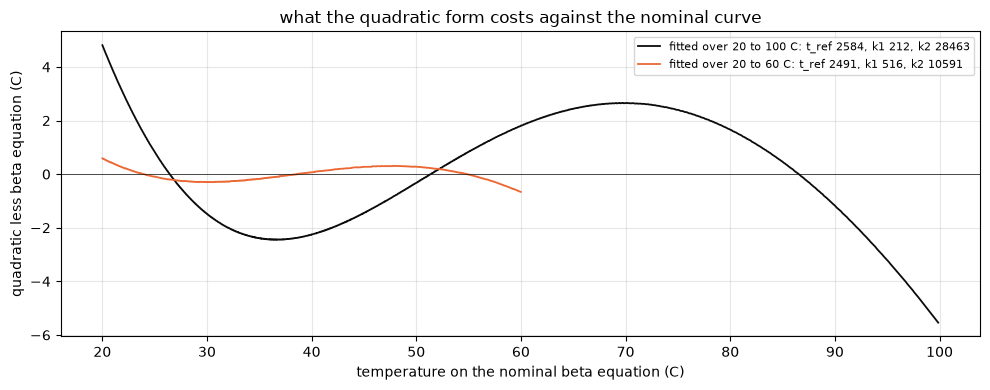

In [8]:
def raw_of_c(t_c):
    # the count the nominal beta equation gives at a temperature: R from the beta equation, then the pull-up divider
    r = BOARD.ntc_r25_ohm * np.exp(BOARD.ntc_beta * (1 / (np.asarray(t_c, float) + 273.15) - 1 / 298.15))
    return BOARD.adc_counts * r / (BOARD.ntc_pullup_ohm + r)

design = {}
for lo, hi in ((20, 100), (20, 60)):
    tg = np.arange(lo, hi + 1e-6, 0.1)                                          # a grid of temperatures over the range, 0.1 C apart
    qd = ntcmod.fit_quadratic(raw_of_c(tg), tg, RAW_REF)                        # the quadratic through the nominal curve, as the design constants
    counts = np.arange(int(np.ceil(raw_of_c(hi))), int(np.floor(raw_of_c(lo))) + 1)   # every integer count the range covers
    resid = ntcmod.quadratic_cc(counts, RAW_REF, *qd) / 100 - BOARD.ntc_c_beta(counts)   # the form's error against the beta equation, in fixed point
    i = int(np.argmax(np.abs(resid)))
    design[(lo, hi)] = {"q": qd, "counts": counts, "resid": resid, "worst": abs(resid[i]), "worst_at_c": BOARD.ntc_c_beta(counts[i])}
    print(f"{lo} to {hi} C, counts {counts.max()} down to {counts.min()}: t_ref {qd[0]} cC, k1 {qd[1]} (Q8.8), k2 {qd[2]} (Q24); "
          f"residual {resid.min():+.2f} to {resid.max():+.2f} C, largest {abs(resid[i]):.2f} C at {BOARD.ntc_c_beta(counts[i]):.0f} C")
DESIGN = design[(20, 100)]                                                      # the service range is the deliverable
fig, ax = plt.subplots(figsize=(10, 4))
for (lo, hi), d, col in (((20, 100), design[(20, 100)], INK), ((20, 60), design[(20, 60)], ORANGE)):
    ax.plot(BOARD.ntc_c_beta(d["counts"]), d["resid"], "-", color=col, lw=1.3, label=f"fitted over {lo} to {hi} C: t_ref {d['q'][0]}, k1 {d['q'][1]}, k2 {d['q'][2]}")
ax.axhline(0, color=INK, lw=0.5)
ax.set_xlabel("temperature on the nominal beta equation (C)"); ax.set_ylabel("quadratic less beta equation (C)")
ax.set_title("what the quadratic form costs against the nominal curve"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Over 20 to 100 C the quadratic in the count misses the beta equation by up to 5.5 C. It reads 4.8 C high at 20 C, 2.5 C low near 37 C, 2.7 C high near 70 C and 5.5 C low at 100 C, and 1.8 C high at 60 C on the way. The beta curve bends too much over 2000 counts for three constants to follow. Over 20 to 60 C the same form holds the beta equation to 0.7 C, a small wave through zero with its largest miss at 60 C, which is inside the meter's class over that range. So the quadratic is a good carrier for the range the thermal experiments use and a poor one for the full service range, and a cutoff near 100 C set through it sits 5 C from where the beta equation puts it. The design can take the beta equation itself, a logarithm and a divide, which the chip has no hardware for, a table, or the quadratic with the stated error, and that is a design call this notebook only prices.

### The results file

The design quadratic over 20 to 100 C with its form error, the refitted beta with the row-choice spread as its bracket and the measured-point quadratic beside it, both noted as fits against a thermocouple shown to read low, the range the fit covers, each plateau's thermocouple reading, count and the conversions' errors, the slope of the gap that followed the board and the gradient with the spread of the fits as their brackets, the gap's constant part at 25 C, the number of rows fitted, and the pad test's rise, loss fraction and bed. The opamp-temperature notebook reads `beta_nominal`, the design conversion, to turn its laps' NTC counts into degrees.

In [9]:
q = results.quantity
plateaus = {p: {"thermocouple_c": q(P.loc[p, "thermocouple_c"], P.loc[p, "thermocouple_c"] - P.loc[p, "tc_sd"], P.loc[p, "thermocouple_c"] + P.loc[p, "tc_sd"], "C"),
                "ntc_raw": q(P.loc[p, "ntc_raw"], P.loc[p, "ntc_raw"] - P.loc[p, "raw_sd"], P.loc[p, "ntc_raw"] + P.loc[p, "raw_sd"], "counts"),
                "bed_c": q(P.loc[p, "bed_c"], unit="C"), "meter_class_c": q(P.loc[p, "meter_class_c"], unit="C"),
                "beta_nominal_error_c": q(P.loc[p, "beta_err"], unit="C"), "beta_nominal_error_rig_out_c": q(P.loc[p, "left_c"], unit="C"),
                "beta_fit_error_c": q(P.loc[p, "beta_fit_err"], unit="C"), "quadratic_error_c": q(P.loc[p, "quad_err"], unit="C")} for p in P.index}
results.write("1-board", "ntc-curve", CAPTURE, pair=BOARD.key,
              notes="board NTC polled on a printer bed with the thermocouple taped to the top surface beside it, no paste; t_c is the thermocouple after its stage 0 "
                    "correction; the nominal beta (registry R25 and beta) is graded against it and is inside the meter's class once the rig's two effects are out, "
                    "the tip's loss through its tape (press-1 pad test) and the bed gradient; design_* is the fixed-point quadratic in the count fitted through the nominal "
                    "beta equation over design_range_c with no thermocouple data in it, design_form_error_c its largest residual against the beta equation "
                    "(lo/hi the residual's range); beta_fit and the refit_* quadratic are fits through the measured points, the plateaus (the last 90 s before the "
                    "mark that ends each) and the cool-down, against a thermocouple shown to read low, so they correct the NTC toward a low reading and are NOT "
                    "design constants; beta_fit's bracket is the spread over the row choices (cool-down alone, whole run); gradient_c_per_c is the gap per C the "
                    "bed sits over the board, the thermocouple reading under the NTC's copper; curve_slope_c_per_c is the nominal beta's gap per C of board with "
                    "the bed at or below the board, which the pad test attributes to the tip's loss; pad_rise_c is the towel's rise over the bare tip on the bed "
                    "(lo the whole padded stretch, hi its highest), tip_loss_fraction that rise over the bed's excess over the room, bed_c_during_pad_test the "
                    "bed's own thermistor (lo/hi its cycling)",
              design_t_ref_cc=q(DESIGN["q"][0], unit="cC"), design_k1_q88=q(DESIGN["q"][1], unit="Q8.8"), design_k2_q24=q(DESIGN["q"][2], unit="Q24"),
              design_range_c=q(100, lo=20, hi=100, unit="C"),
              design_form_error_c=q(DESIGN["worst"], lo=DESIGN["resid"].min(), hi=DESIGN["resid"].max(), unit="C"),
              beta_nominal=q(BOARD.ntc_beta, unit="K"),
              beta_fit=q(beta_fit, lo=min(b for b, _ in checks.values()), hi=max(b for b, _ in checks.values()), unit="K"),
              refit_raw_ref=q(RAW_REF, unit="counts"), refit_t_ref_cc=q(quad[0], unit="cC"),
              refit_k1_q88=q(quad[1], unit="Q8.8"), refit_k2_q24=q(quad[2], unit="Q24"),
              range_c=q(fit["t_c"].max(), lo=fit["t_c"].min(), hi=fit["t_c"].max(), unit="C"),
              fit_rows=q(len(fit), unit="count"),
              curve_slope_c_per_c=q(slope, lo=slope_lo, hi=slope_hi, unit="C/C"),
              gradient_c_per_c=q(grad, lo=grad_lo, hi=grad_hi, unit="C/C"),
              gap_at_25_c=q(c0["const"], lo=c0["const"] - s0["const"], hi=c0["const"] + s0["const"], unit="C"),
              pad_rise_c=q(pad_rise, lo=pad_rise_lo, hi=pad_rise_hi, unit="C"),
              tip_loss_fraction=q(loss, lo=loss_lo, hi=loss_hi, unit="C/C"),
              bed_c_during_pad_test=q(bed_test.mean(), lo=bed_test.min(), hi=bed_test.max(), unit="C"),
              plateaus=plateaus)

PosixPath('stages/1-board/ntc-curve/results/dev-v006-2A-D.json')

## Limitations

- The thermocouple tip sits in still room air under a strip of kapton with no paste, and the pad test shows a tip taped that way reads under the surface by at least 13 % of the surface's excess over the room. On the board that is the 0.061 C per C part of the gap, about 2.7 C at the hot plateau, so the grade of the nominal curve carries about 2 C of slack from the rig on top of the meter's class, and the refitted constants are corrections toward a thermocouple that reads low. A run with paste under the tip and a firm tape is what takes that slack out.
- The board is heated from underneath, so the thermocouple on the top surface reads under the NTC's copper by about 0.05 to 0.07 C per C the bed sits over the board, about 1.2 C at the hot plateau. The opamp-temperature experiment runs on the same bed, so the same gradient is in its plateaus.
- The meter bounds every absolute number. Its temperature class is 1 % of the reading plus 0.5 C, 0.7 C at room and 1.1 C at 60 C. The thermocouple's own offset and slope are the stage 0 result and are small against the class.
- The pad test's bed is read by the bed's own thermistor, which is not a calibrated reference, so the loss fraction is against the thermistor's excess over the room and is a lower bound, since the covered tip was still climbing.
- The range is 24 to 60 C, as far as the bed's 80 C took the board. The design quadratic over 20 to 100 C is graded against the beta equation alone above that, not against the thermocouple.
- The plateaus were still creeping by 0.15 to 0.25 C per minute, so each plateau mean is a point on a slow ramp and not a settled value.
- One board, one run. The refitted beta's bracket is the spread over the row choices, not run to run.
- The whole board is not at one temperature. The bed's thermistor reads the heater under the air gap, 13 to 20 C over the board on the plateaus, and `heater.csv` is a side note on the rig and not a reference.
- The NTC's own dissipation in its pull-up, 0.16 to 0.27 mW, is under about 0.3 C by the usual dissipation constants in still air and was not measured.

## Open questions

- The grade to the meter's class. A repeat of this capture with thermal paste under the tip and a firm tape over it is the first run to make. The tip's loss then goes to near zero, the gap that follows the board's temperature goes with it if the pad test's reading is right, and whatever is left against the nominal beta is the curve, graded to the class. A gap that stays at 0.061 C per C with paste under the tip would put the pad test's reading in doubt and send it back to the curve.
- Which constant of the curve is off, if any. The NTC and its pull-up read on the meter's ohms range with the board unpowered, at room beside the thermocouple and again on the hot plateau, is now a check rather than the separator. An R25 or pull-up off nominal shows at room, where the meter's ohms class is 0.5 % of the reading, and a beta off nominal shows only at the hot reading.
- Whether the gradient is what this run reads it as. A second thermocouple on the bottom copper with thermal paste, logged beside the one on top, reads the gradient across the board directly. Or the board heated by its own driver instead of the bed, laps on the bare load at a high level with the bed off, puts the heat inside the board and the gradient the other way round.
- Whether the board's own heat moves the NTC. The opamp-temperature capture drives laps on the heated board with the NTC in every row, so a step in the count during a lap against the rest before it is the driver's heat reaching the NTC, and that capture answers it.
- The curve above 60 C. A run with the bed at 100 C puts the board near 80 C and grades the nominal beta there, where the design quadratic's form error is largest.
- The refitted beta's run to run spread. A repeat of this capture on the same rig gives it, and one with the cool-down taken to room gives the gap's constant part at the low end on the way down as well as up.

## Conclusion

Against the thermocouple on the top surface, the board NTC's nominal beta equation, 10 kohm at 25 C and 3950 K, reads 0.6 C high at room, 2.7 C high at 47 C and 4.1 C high at 60 C. The rig owns that gap. The bed heating the board from underneath leaves the thermocouple under the NTC's copper by 0.046 to 0.066 C per C the bed sits over the board, 1.2 C at the hot plateau, and the tip taped without paste loses heat to the room air through its tape, which the pad test shows directly, a 7.6 C rise under a towel on a bed 56 C over the room, at least 13 % of the excess, and that covers the 0.061 C per C part of the gap that followed the board's own temperature, 2.7 C at 60 C. With both out, the nominal beta is within 0.2 C of the thermocouple at every plateau, inside the meter's class of 1 % plus 0.5 C, with about 2 C of slack from the rig on top of the class.

The design conversion is the nominal beta equation. Where a fixed-point quadratic in the count is carried instead, the fit through the beta equation over 20 to 100 C is t_ref 2584 cC, k1 212 and k2 28463 at a reference count of 2048, and that form misses the beta equation by up to 5.5 C over the range, 1.8 C at 60 C and 5.5 C at 100 C. Over 20 to 60 C the form holds it to 0.7 C with t_ref 2491, k1 516 and k2 10591. The refitted beta of 4331 K, 4316 to 4383 K over the row choices, and the quadratic through the measured points, t_ref 2482, k1 452 and k2 11195, are what this thermocouple placement gives, corrections toward a thermocouple that reads low, and they are not design constants. The opamp-temperature notebook reads the nominal beta for its plateau temperatures.

The run to make next is this one with thermal paste under the tip and a firm tape over it, which takes the tip's loss out and grades the nominal curve to the meter's class. The gradient's size and the curve above 60 C are the other two open items, each named above with the capture that settles it.